In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
from scipy import stats
import pandas as pd
import seaborn as sns

# Set random seed for reproducibility
key = jax.random.PRNGKey(42)
np.random.seed(42)

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
x = jnp.ones(m)  # Input odour signal

# Load and validate optimised parameters


In [2]:
# Naka-Rushton function
def nr(x, n=4):
    """Naka-Rushton activation function"""
    return x**n / (x**n + 1)

# Unpack parameters
def unpack_theta(theta, m):
    idx = 0
    w_osn_r = theta[idx:idx+m]; idx += m
    w_osn_b = theta[idx:idx+m]; idx += m
    w_osn_g = theta[idx:idx+m]; idx += m
    w_osn_y = theta[idx:idx+m]; idx += m
    w_b_r = theta[idx:idx+m]; idx += m
    w_b_g = theta[idx:idx+m]; idx += m
    w_b_y = theta[idx:idx+m]; idx += m
    w_r_y = theta[idx:idx+m]; idx += m
    w_r_g = theta[idx:idx+m]; idx += m
    alpha = theta[idx:idx+m]; idx += m
    W_g_r = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    W_g_y = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y

# Fixed-point function for green neurons
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
    """Fixed point equation for green neurons"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input)
    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input)
    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input)
    return g_new

# Solve fixed point via Anderson Acceleration
def solve_fixed_point(theta, x, m):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)
    aa = AndersonAcceleration(mitral_fixed_point, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output
def mitral_output(theta, x, m):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g = solve_fixed_point(theta, x, m)
    b = nr(w_osn_b * alpha * x)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r)
    return r, g, b, y

In [24]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_1000_samples_n_4_target_0.5.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (1000, 28)
Number of samples: 1000
Number of parameters per sample: 28


In [25]:
def check_single_theta_np(theta, x, m):
    """Check single theta sample - using numpy for compatibility"""
    r, g, b, y = mitral_output(theta, x, m)
    # Convert to numpy arrays
    r = np.array(r)
    g = np.array(g)
    b = np.array(b)
    y = np.array(y)

    # Check if all elements are in [0.4, 0.6]
    r_ok = (r >= 0.4).all() and (r <= 0.6).all()
    g_ok = (g >= 0.4).all() and (g <= 0.6).all()
    b_ok = (b >= 0.4).all() and (b <= 0.6).all()
    y_ok = (y >= 0.4).all() and (y <= 0.6).all()

    return r_ok and g_ok and b_ok and y_ok

# Process samples
n_samples = theta_opt.shape[0]
valid_mask = np.zeros(n_samples, dtype=bool)

for i in range(n_samples):
    theta_star = jnp.array(theta_opt[i, :])
    valid_mask[i] = check_single_theta_np(theta_star, x, m)

    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{n_samples} samples...")

theta_opt = theta_opt[valid_mask]

print(f"Number of valid theta_opt: {theta_opt.shape[0]} out of {n_samples}")

Processed 100/1000 samples...
Processed 200/1000 samples...
Processed 300/1000 samples...
Processed 400/1000 samples...
Processed 500/1000 samples...
Processed 600/1000 samples...
Processed 700/1000 samples...
Processed 800/1000 samples...
Processed 900/1000 samples...
Processed 1000/1000 samples...
Number of valid theta_opt: 982 out of 1000


In [40]:
input_values = np.linspace(0, 2, 10)
n_samples = 2

y_average = np.zeros((n_samples, len(input_values)))

for j in range(n_samples):
    for i in range(len(input_values)):
        x_input = jnp.ones(m) * input_values[i]
        r, g, b, y = mitral_output(theta_opt[j], x_input, m)
        y_average[j, i] = np.mean(y)

print(y_average.shape)

(2, 10)


sample: 0
sample: 1
sample: 2
sample: 3
sample: 4
sample: 5
sample: 6
sample: 7
sample: 8
sample: 9


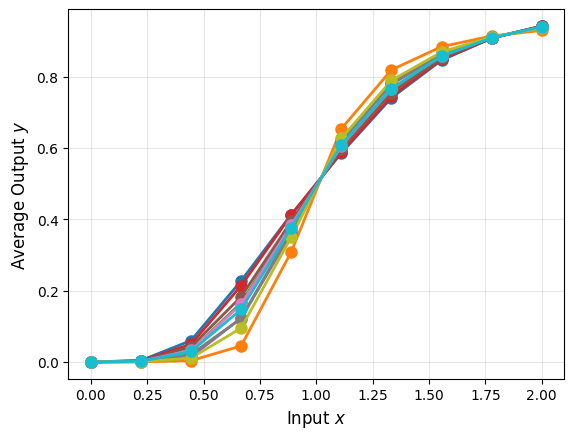

In [43]:
input_values = np.linspace(0, 2, 10)
n_samples = 10

y_average = np.zeros((n_samples, len(input_values)))

for j in range(n_samples):
    print("sample:", j)
    for i in range(len(input_values)):
        x_input = jnp.ones(m) * input_values[i]
        r, g, b, y = mitral_output(theta_opt[j], x_input, m)
        y_average[j, i] = np.mean(y)


# Plot average of y_1 and y_2 for each sample j
for k in range(n_samples):
    plt.plot(input_values, y_average[k], 'o-', linewidth=2, markersize=8)
plt.xlabel('Input $x$', fontsize=12)
plt.ylabel('Average Output $y$', fontsize=12)
#plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)

sample: 0
sample: 1
sample: 2
sample: 3
sample: 4
sample: 5
sample: 6
sample: 7
sample: 8
sample: 9
sample: 10
sample: 11
sample: 12
sample: 13
sample: 14
sample: 15
sample: 16
sample: 17
sample: 18
sample: 19


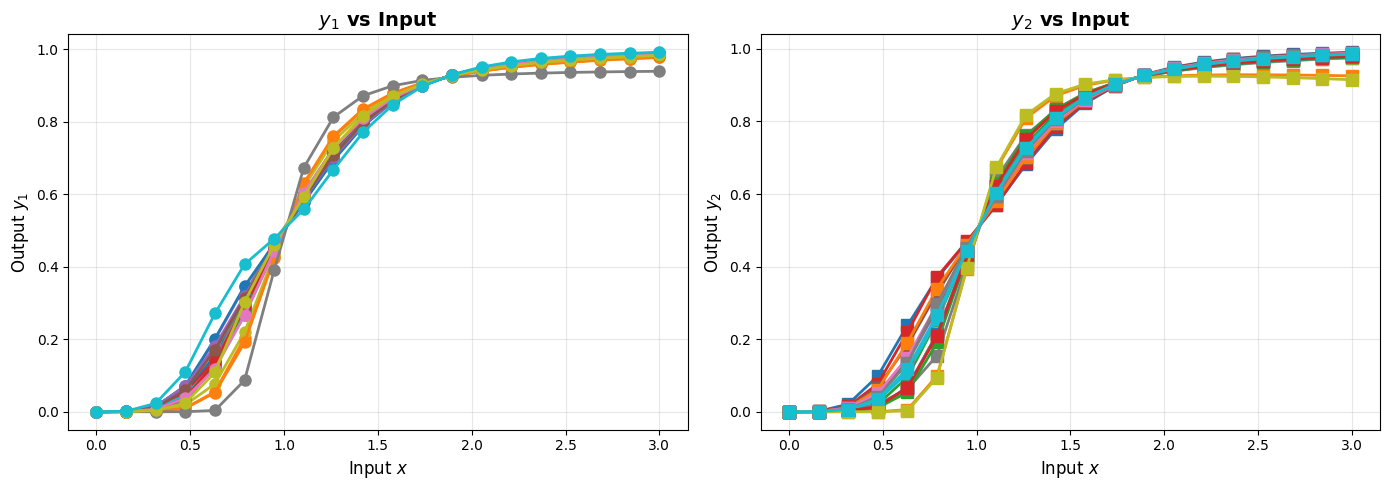

In [48]:
input_values = np.linspace(0, 3, 20)
n_samples = 20

y_0 = np.zeros((n_samples, len(input_values)))
y_1 = np.zeros((n_samples, len(input_values)))

for j in range(n_samples):
    print("sample:", j)
    for i in range(len(input_values)):
        x_input = jnp.ones(m) * input_values[i]
        r, g, b, y = mitral_output(theta_opt[j], x_input, m)
        y_0[j, i] = np.array(y)[0]
        y_1[j, i] = np.array(y)[1]


# Plot y_0 and y_1 in two separate subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: y_0 for each sample
ax1 = axes[0]
for k in range(n_samples):
    ax1.plot(input_values, y_0[k], 'o-', linewidth=2, markersize=8)
ax1.set_xlabel('Input $x$', fontsize=12)
ax1.set_ylabel('Output $y_1$', fontsize=12)
ax1.set_title('$y_1$ vs Input', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)

# Plot 2: y_1 for each sample
ax2 = axes[1]
for k in range(n_samples):
    ax2.plot(input_values, y_1[k], 's-', linewidth=2, markersize=8)
ax2.set_xlabel('Input $x$', fontsize=12)
ax2.set_ylabel('Output $y_2$', fontsize=12)
ax2.set_title('$y_2$ vs Input', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

sample: 0
sample: 1
sample: 2
sample: 3
sample: 4
sample: 5
sample: 6
sample: 7
sample: 8
sample: 9


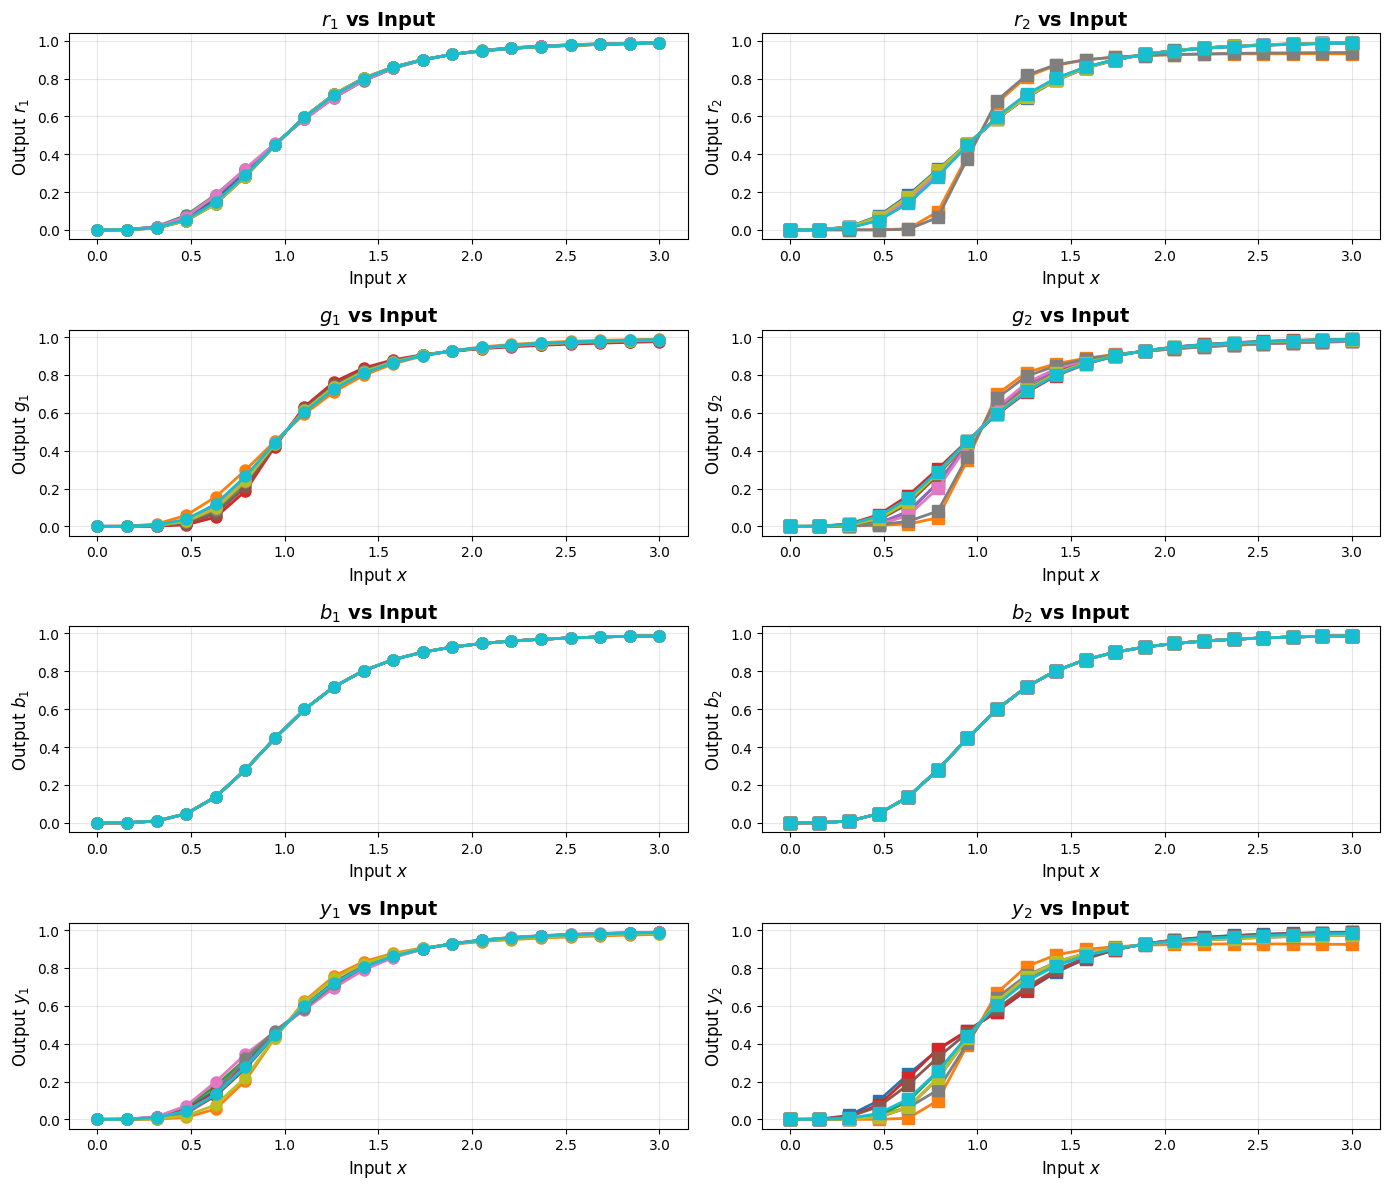

In [53]:
input_values = np.linspace(0, 3, 20)
n_samples = 10

r_0 = np.zeros((n_samples, len(input_values)))
r_1 = np.zeros((n_samples, len(input_values)))
g_0 = np.zeros((n_samples, len(input_values)))
g_1 = np.zeros((n_samples, len(input_values)))
b_0 = np.zeros((n_samples, len(input_values)))
b_1 = np.zeros((n_samples, len(input_values)))
y_0 = np.zeros((n_samples, len(input_values)))
y_1 = np.zeros((n_samples, len(input_values)))

for j in range(n_samples):
    print("sample:", j)
    for i in range(len(input_values)):
        x_input = jnp.ones(m) * input_values[i]
        r, g, b, y = mitral_output(theta_opt[j], x_input, m)
        r_0[j, i] = np.array(r)[0]
        r_1[j, i] = np.array(r)[1]
        g_0[j, i] = np.array(g)[0]
        g_1[j, i] = np.array(g)[1]
        b_0[j, i] = np.array(b)[0]
        b_1[j, i] = np.array(b)[1]
        y_0[j, i] = np.array(y)[0]
        y_1[j, i] = np.array(y)[1]


# Plot y_0 and y_1 in two separate subplots
fig, axes = plt.subplots(4, 2, figsize=(14, 12))
axes = axes.flatten()  # Flatten the 2D array to 1D

# Plot 3: r_0 for each sample
ax1 = axes[0]
for k in range(n_samples):
    ax1.plot(input_values, r_0[k], 'o-', linewidth=2, markersize=8)
ax1.set_xlabel('Input $x$', fontsize=12)
ax1.set_ylabel('Output $r_1$', fontsize=12)
ax1.set_title('$r_1$ vs Input', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)

# Plot 4: r_1 for each sample
ax2 = axes[1]
for k in range(n_samples):
    ax2.plot(input_values, r_1[k], 's-', linewidth=2, markersize=8)
ax2.set_xlabel('Input $x$', fontsize=12)
ax2.set_ylabel('Output $r_2$', fontsize=12)
ax2.set_title('$r_2$ vs Input', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)


# Plot 5: g_0 for each sample
ax3 = axes[2]
for k in range(n_samples):
    ax3.plot(input_values, g_0[k], 'o-', linewidth=2, markersize=8)
ax3.set_xlabel('Input $x$', fontsize=12)
ax3.set_ylabel('Output $g_1$', fontsize=12)
ax3.set_title('$g_1$ vs Input', fontsize=14, fontweight='bold')
ax3.grid(True, alpha=0.3)

# Plot 6: g_1 for each sample
ax4 = axes[3]
for k in range(n_samples):
    ax4.plot(input_values, g_1[k], 's-', linewidth=2, markersize=8)
ax4.set_xlabel('Input $x$', fontsize=12)
ax4.set_ylabel('Output $g_2$', fontsize=12)
ax4.set_title('$g_2$ vs Input', fontsize=14, fontweight='bold')
ax4.grid(True, alpha=0.3)

# Plot 7: b_0 for each sample
ax5 = axes[4]   
for k in range(n_samples):
    ax5.plot(input_values, b_0[k], 'o-', linewidth=2, markersize=8)
ax5.set_xlabel('Input $x$', fontsize=12)
ax5.set_ylabel('Output $b_1$', fontsize=12)
ax5.set_title('$b_1$ vs Input', fontsize=14, fontweight='bold')
ax5.grid(True, alpha=0.3)   

# Plot 8: b_1 for each sample
ax6 = axes[5]
for k in range(n_samples):
    ax6.plot(input_values, b_1[k], 's-', linewidth=2, markersize=8)
ax6.set_xlabel('Input $x$', fontsize=12)    
ax6.set_ylabel('Output $b_2$', fontsize=12)
ax6.set_title('$b_2$ vs Input', fontsize=14, fontweight='bold')
ax6.grid(True, alpha=0.3)

# Plot 1: y_0 for each sample
ax7 = axes[6]
for k in range(n_samples):
    ax7.plot(input_values, y_0[k], 'o-', linewidth=2, markersize=8)
ax7.set_xlabel('Input $x$', fontsize=12)
ax7.set_ylabel('Output $y_1$', fontsize=12)
ax7.set_title('$y_1$ vs Input', fontsize=14, fontweight='bold')
ax7.grid(True, alpha=0.3)

# Plot 2: y_1 for each sample
ax8 = axes[7]
for k in range(n_samples):
    ax8.plot(input_values, y_1[k], 's-', linewidth=2, markersize=8)
ax8.set_xlabel('Input $x$', fontsize=12)
ax8.set_ylabel('Output $y_2$', fontsize=12)
ax8.set_title('$y_2$ vs Input', fontsize=14, fontweight='bold')
ax8.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()